# Defining the Game: Tic-Tac-Toe

## The Search Problem

A general search problem is defined in the following way:

* **Initial State:** Empty $3 \times 3$ board. It is the move for $x$.
* **Actions:** Place your symbol on any empty square.
* **Transition function:** You symbol is placed on the board according to the action. The opponent
    places her symbol. From our viewpoint this makes the environment non-deterministic.
* **Goal state:** A win (three symbols in a row, column or diagonal). 
* **Path cost:** number of moves.
  
Since Tic-tac-toe is a game, we will use the more specializes components (see Chapter 5):
* `Actions(s)` Legal moves in state s.
* `Result(s, a)` Transition model.
* `Terminal(s)` Test for terminal states.
* `Utility(s)` Utility for player Max for terminal states.

**Notes:**

* To define the goal state we will use a test for a **terminal state** (game is over) and a **utility function** (win or loose). 
* We will use DFS which is not optimal. So will probably not find the solution with the lowest path cost, i.e., win with the smallest number of moves. Therefore, we drop the path cost all together.

## Problem Size

### State Space Estimates

Each state is a possible board. Each of the 9 squares can have 3 values (empty, x and o), but some boards are impossible (where a player has several sequences of 3).The number of states in the state space graph is less than $3^9$.

In [1]:
3**9

19683

A tighter bound for the search space size would be looking at all the ways we can choose $i = 1,2,3,...,9$ places from the board given by ${9 \choose i}$. Now we need to find all ways how we can choose half the symbols for player o which is given by ${i \choose \lfloor \frac{i}{2} \rfloor}$. 
Put together we get $\sum_{i=1}^9{{9 \choose i}{i \choose \lfloor \frac{i}{2} \rfloor}}$.

In [2]:
import math

print("level\tboards")
sum = 0

for i in range(1,9):
    sum += math.comb(9, i) * math.comb(i, math.floor(i/2))
    print(i, "\t", math.comb(9, i) , " x ", math.comb(i, math.floor(i/2)) , " = ",  math.comb(9, i) * math.comb(i, math.floor(i/2)))

sum

level	boards
1 	 9  x  1  =  9
2 	 36  x  2  =  72
3 	 84  x  3  =  252
4 	 126  x  6  =  756
5 	 126  x  10  =  1260
6 	 84  x  20  =  1680
7 	 36  x  35  =  1260
8 	 9  x  70  =  630


5919

This is an upper bound since it contains some infeasible boards where both players have 3 in a row.

### Space and Time Complexity Using the Search Tree Estimates

For solving the problem, we use the search tree which can be significantly larger than the state space.
A search tree is a subgraph with all **cycles removed.** The standard implementation of DFS **cannot remove redundant paths** (i.e., getting to the same board by plcing symbols in a different order). Therefore, a state can be represented by several nodes in different branches! We observe the following:

* The complete search tree has a maximal depth $m=9$
* The max branching factor $b=9$ (for first move).

DFS has

* a space complexity of $O(bm)$ (current path plus frontier) and 
* a time complecity of $O(b^m)$ (number of expanded nodes).

In [3]:
# Space Complexity O(bm):
9*9

81

In [4]:
# Time Complexity O(b^m): 
9**9

387420489

The branching factor decreases after each move. The first level has a branching factor of 9, the second a branching factor of 8, etc. The total number of nodes is:

| <div style="width:100px">Level</div>      |  <div style="width:200px"># of nodes</div>   |
| :------------- | :---------------- |
| root       | $1$ |
| level 1    | $9 = 9!/8!$ |
| level 2    | $9 \times 8 = 9!/7!$ |
| level 2    | $9 \times 8 \times 7 = 9!/6!$ |
| ...        |  ... |
| level 9    | $9 \times 8 \times \dots \times 2 \times 1 = 9!$ |

The total number of game tree nodes is less (some games end early) than the sum of the nodes above. The upper bound for the number of nodes is

$\sum_{i = 0}^9 \frac{9!}{i!}$

In [5]:
sum = 1
partial_fac = 1
print("level\t# nodes")
print("root\t 1")

for i in range(9, 0, -1):
    partial_fac *= i
    sum += partial_fac 
    print(10-i, "\t", partial_fac)
    
sum

level	# nodes
root	 1
1 	 9
2 	 72
3 	 504
4 	 3024
5 	 15120
6 	 60480
7 	 181440
8 	 362880
9 	 362880


986410

Since some sequences are cut short because of a win, we expect fewer nodes in the game complete tree.

**Redundant paths:** The tree size estimation contains redundant paths.

**Cycles:** Tic-tac-toe does not have cycles (you cannot remove a played symbol).


__Note:__ This size makes tic-tac-toe a very small problem that can be easily solved by tree search. Most games and real problems are too large and cannot be solved this way. For example, chess has an estimated state space size of $>10^{30}$. 
We will learn several methods that address this problem later.

## Implementation

We need to implement the following functions:

* `Actions(s)` Legal moves in state s.
* `Result(s, a)` Transition model.
* `Terminal(s)` Test for terminal states.
* `Utility(s)` Utility for player Max for terminal states.

The state (a board position) will be implemented as a vector (in Python this is a list) of length 9. The values are `' ', 'x', 'o'`. The actions are just the index in the list (0, 1, 2, ..., 8).


The implementation of these and some other helper functions can be found in [tictactoe.py](tictactoe.py)
and be imported from that file

In [6]:
# download if missing
import urllib.request
import os

def download(file, base_url):
    if not os.path.exists(file):
        urllib.request.urlretrieve(base_url + file, file)

download("tictactoe.py", ".")

In [7]:
from tictactoe import empty_board, actions, result, terminal, utility
from tictactoe import show_board, show_board_text

## Examples

In [8]:
board = empty_board()
board[0] = 'x'; board[3] = 'x'; board[6] = 'x'; board[1] = 'o'; board[4] = 'o'  
display(board)

['x', 'o', ' ', 'x', 'o', ' ', 'x', ' ', ' ']

In [9]:
show_board_text(board)

[['x' 'o' ' ']
 ['x' 'o' ' ']
 ['x' ' ' ' ']]


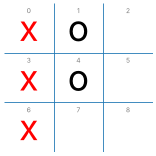

In [10]:
show_board(board)

In [11]:
actions(board)

[2, 5, 7, 8]

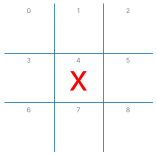

In [12]:
board2 = empty_board()
board2 = result(board2, 'x', 4)
show_board(board2)

In [13]:
print(terminal(board))
print(terminal(board2))

True
False


## Experiments


### Baseline: Randomized Player

A completely randomized player agent can be used as a weak baseline. A simple random agent and a the game environment
are implemented in [tictactoe.py](tictactoe.py) as `random_player()` and `play()`, respectively.

In [14]:
from tictactoe import random_player, play 

### Random vs. Random

Let a random player play another random player for 100 games and look at the number of wins.

In [15]:
%time display(play(random_player, random_player, N = 100))

{'x': 58, 'o': 29, 'd': 13}

CPU times: user 23 ms, sys: 469 μs, total: 23.5 ms
Wall time: 23.5 ms


_Note:_ It looks like the first player (x) has an advantage!

---
# Lab 05 – Bài 1: Thực hành bổ sung (kết quả chạy và nhận xét)

> Các ô phía trên là nội dung gốc của giảng viên và được giữ nguyên. Từ đây trở xuống là phần **bổ sung theo yêu cầu của đề Lab 05 – Bài 1**:
> xác định cách biểu diễn trạng thái, hành động hợp lệ, mô hình chuyển trạng thái, trạng thái kết thúc, hàm lợi ích và chạy thực nghiệm cơ sở (Random vs. Random, 1.000 ván).

## 1. Mô hình trò chơi Tic-Tac-Toe

| Thành phần | Hàm trong `tictactoe.py` | Ý nghĩa |
|---|---|---|
| Trạng thái `s` | `list` gồm 9 phần tử `' '`, `'x'`, `'o'` | Ô thứ `i` nằm ở hàng `i // 3`, cột `i % 3` (đúng với số nhỏ màu xám do `show_board()` vẽ) |
| `Actions(s)` | `actions(board)` | Danh sách chỉ số các ô còn trống |
| `Result(s, a)` | `result(state, player, action)` | Trả về **bản sao** bàn cờ sau khi `player` đánh vào ô `action` (ném `Exception` nếu ô đã có quân) |
| `Terminal(s)` | `terminal(state)` | `True` nếu có người thắng hoặc bàn cờ đã đầy |
| `Utility(s)` | `utility(state, player)` | `+1` nếu `player` thắng, `-1` nếu thua, `0` nếu hòa, `None` nếu chưa kết thúc. Người chơi **Max** là `'x'` |
| Hàm phụ | `check_board(state)` | Trả về `'x'`, `'o'` (có người thắng), `'d'` (hòa) hoặc `'n'` (chưa kết thúc) |

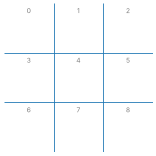

actions(board) = [0, 1, 2, 3, 4, 5, 6, 7, 8]


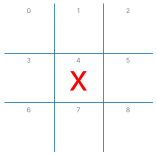

actions(board) sau khi x đánh ô 4 = [0, 1, 2, 3, 5, 6, 7, 8]


In [16]:
# Ví dụ đúng như đề bài: bàn cờ rỗng -> các hành động hợp lệ -> x đánh vào ô số 4 (ô giữa)
board = empty_board()
show_board(board)
print("actions(board) =", actions(board))

board = result(board, 'x', 4)
show_board(board)
print("actions(board) sau khi x đánh ô 4 =", actions(board))

**Nhận xét.** Ở bàn cờ rỗng có 9 hành động hợp lệ (`0..8`). Sau khi `x` đánh vào ô số 4 chỉ còn 8 hành động, ô 4 biến mất khỏi `actions()`.
`result()` không sửa bàn cờ cũ mà trả về một bản sao mới – điều này rất quan trọng cho các thuật toán tìm kiếm (DFS/Minimax) vì mỗi nhánh của cây cần một trạng thái độc lập.

In [17]:
# result() trả về bản sao và từ chối hành động bất hợp lệ
b0 = empty_board()
b1 = result(b0, 'x', 4)
print("b0 (không bị thay đổi):", b0)
print("b1                    :", b1)

try:
    result(b1, 'o', 4)        # ô 4 đã có quân x
except Exception as e:
    print("Lỗi mong đợi ->", e)

b0 (không bị thay đổi): [' ', ' ', ' ', ' ', ' ', ' ', ' ', ' ', ' ']
b1                    : [' ', ' ', ' ', ' ', 'x', ' ', ' ', ' ', ' ']
Lỗi mong đợi -> Illegal action 4 by player o!


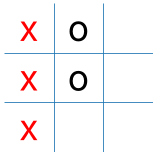

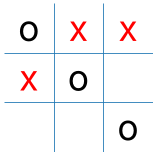

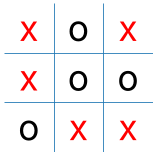

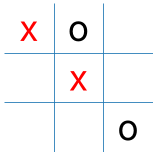

,Trạng thái,check_board,terminal,utility(x),utility(o)
0,x thắng (cột 0),x,True,1,-1
1,o thắng (đường chéo),o,True,-1,1
2,Hòa (bàn cờ đầy),d,True,0,0
3,Đang chơi (chưa kết thúc),n,False,None,None


In [18]:
# terminal(), utility() và check_board() trên 4 loại trạng thái
from tictactoe import check_board

cases = {
    "x thắng (cột 0)"       : ['x','o',' ', 'x','o',' ', 'x',' ',' '],
    "o thắng (đường chéo)"  : ['o','x','x', 'x','o',' ', ' ',' ','o'],
    "Hòa (bàn cờ đầy)"      : ['x','o','x', 'x','o','o', 'o','x','x'],
    "Đang chơi (chưa kết thúc)": ['x','o',' ', ' ','x',' ', ' ',' ','o'],
}

import pandas as pd
rows = []
for name, b in cases.items():
    rows.append({"Trạng thái": name,
                 "check_board": check_board(b),
                 "terminal": terminal(b),
                 "utility(x)": str(utility(b, 'x')),
                 "utility(o)": str(utility(b, 'o'))})
    show_board(b, help=False)
display(pd.DataFrame(rows))

**Nhận xét.** `utility()` được tính từ góc nhìn của người chơi truyền vào: cùng một bàn cờ nhưng `utility(x) = +1` thì `utility(o) = -1` (trò chơi **tổng bằng không**).
Với trạng thái chưa kết thúc `utility()` trả về `None`, nên thuật toán tìm kiếm phải kiểm tra `terminal`/`utility is not None` trước khi dùng giá trị.

In [19]:
# Kích thước thực tế của không gian trạng thái và cây trò chơi (đếm chính xác bằng đệ quy có nhớ)
from functools import lru_cache
from tictactoe import check_board, other

@lru_cache(maxsize=None)
def count_nodes(state, player):
    """số nút của cây trò chơi (không gộp trạng thái trùng) bắt đầu từ state"""
    b = list(state)
    if check_board(b) != 'n':
        return 1
    total = 1
    for a in actions(b):
        total += count_nodes(tuple(result(b, player, a)), other(player))
    return total

@lru_cache(maxsize=None)
def count_games(state, player):
    """số ván chơi khác nhau"""
    b = list(state)
    if check_board(b) != 'n':
        return 1
    total = 0
    for a in actions(b):
        total += count_games(tuple(result(b, player, a)), other(player))
    return total

start = tuple(empty_board())
reachable, terminal_states = {start}, 0
frontier = [(start, 'x')]
while frontier:
    nxt = []
    for s, p in frontier:
        if check_board(list(s)) != 'n':
            terminal_states += 1
            continue
        for a in actions(list(s)):
            c = tuple(result(list(s), p, a))
            if c not in reachable:
                reachable.add(c); nxt.append((c, other(p)))
    frontier = nxt

print(f"Cận trên 3^9                         = {3**9:,}")
print(f"Số bàn cờ hợp lệ có thể đạt được     = {len(reachable):,}")
print(f"  trong đó trạng thái kết thúc       = {terminal_states:,}")
print(f"Số nút của cây trò chơi đầy đủ       = {count_nodes(start, 'x'):,}")
print(f"Số ván chơi khác nhau                = {count_games(start, 'x'):,}")

Cận trên 3^9                         = 19,683
Số bàn cờ hợp lệ có thể đạt được     = 5,478
  trong đó trạng thái kết thúc       = 958
Số nút của cây trò chơi đầy đủ       = 549,946


Số ván chơi khác nhau                = 255,168


**Nhận xét.** Không gian trạng thái thật sự chỉ có **5.478** bàn cờ hợp lệ (nhỏ hơn rất nhiều so với cận trên $3^9 = 19.683$), nhưng cây trò chơi có **549.946 nút** vì cùng một bàn cờ được đạt tới bằng nhiều thứ tự nước đi khác nhau (DFS không loại được đường đi dư thừa).
Đây cũng chính là số nút mà Minimax đầy đủ phải duyệt ở bàn cờ rỗng (xem notebook Minimax). Tic-Tac-Toe đủ nhỏ để giải trọn vẹn, còn các trò chơi lớn hơn (Connect 4, Dots and Boxes) thì không.

## 2. Thực nghiệm cơ sở: Random vs. Random (1.000 ván)

Hai `random_player` chơi với nhau 1.000 ván bằng `play()`. `x` luôn đi trước. Để kết quả lặp lại được, ô dưới cố định `seed`.

Kết quả 1000 ván Random vs. Random: {'x': 596, 'o': 282, 'd': 122}
  X thắng:  59.6%   O thắng:  28.2%   Hòa:  12.2%
  Thời gian: 397 ms cho 1000 ván


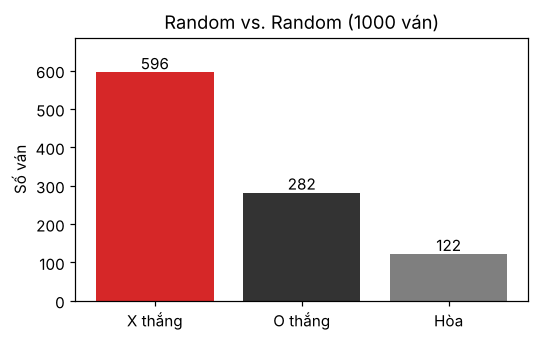

In [20]:
import time
import numpy as np
import matplotlib.pyplot as plt

np.random.seed(2026)
N = 1000
t0 = time.perf_counter()
res = play(random_player, random_player, N = N)
dt = time.perf_counter() - t0

print(f"Kết quả {N} ván Random vs. Random: {res}")
print(f"  X thắng: {res['x']/N:6.1%}   O thắng: {res['o']/N:6.1%}   Hòa: {res['d']/N:6.1%}")
print(f"  Thời gian: {dt*1000:.0f} ms cho {N} ván")

fig, ax = plt.subplots(figsize=(5, 3.2), dpi=110)
bars = ax.bar(["X thắng", "O thắng", "Hòa"], [res['x'], res['o'], res['d']], color=["#d62728", "#333333", "#7f7f7f"])
for b in bars:
    ax.text(b.get_x() + b.get_width()/2, b.get_height() + 8, int(b.get_height()), ha="center")
ax.set_ylabel("Số ván"); ax.set_title(f"Random vs. Random ({N} ván)")
ax.set_ylim(0, max(res.values()) * 1.15)
plt.tight_layout(); plt.show()

In [21]:
# So sánh với xác suất chính xác (duyệt toàn bộ cây trò chơi khi mọi nước đi đều ngẫu nhiên đều)
@lru_cache(maxsize=None)
def exact_prob(state, player):
    b = list(state)
    g = check_board(b)
    if g == 'x': return (1.0, 0.0, 0.0)
    if g == 'o': return (0.0, 1.0, 0.0)
    if g == 'd': return (0.0, 0.0, 1.0)
    acts = actions(b)
    px = po = pd_ = 0.0
    for a in acts:
        r = exact_prob(tuple(result(b, player, a)), other(player))
        px += r[0] / len(acts); po += r[1] / len(acts); pd_ += r[2] / len(acts)
    return (px, po, pd_)

px, po, pd_ = exact_prob(start, 'x')
print(f"Xác suất lý thuyết : X thắng {px:6.2%} | O thắng {po:6.2%} | Hòa {pd_:6.2%}")
print(f"Thực nghiệm (1000) : X thắng {res['x']/N:6.2%} | O thắng {res['o']/N:6.2%} | Hòa {res['d']/N:6.2%}")

# độ dao động giữa các lần chạy 1000 ván
runs = [play(random_player, random_player, N = 1000) for _ in range(5)]
print()
print("5 lần chạy độc lập (mỗi lần 1000 ván):")
for r in runs:
    print("  ", r)

Xác suất lý thuyết : X thắng 58.49% | O thắng 28.81% | Hòa 12.70%
Thực nghiệm (1000) : X thắng 59.60% | O thắng 28.20% | Hòa 12.20%



5 lần chạy độc lập (mỗi lần 1000 ván):
   {'x': 599, 'o': 284, 'd': 117}
   {'x': 581, 'o': 296, 'd': 123}
   {'x': 602, 'o': 273, 'd': 125}
   {'x': 603, 'o': 287, 'd': 110}
   {'x': 576, 'o': 291, 'd': 133}


**Nhận xét – lợi thế của người đi trước.**
* Với 1.000 ván, kết quả thực nghiệm xấp xỉ giá trị lý thuyết (X ≈ 58,5%, O ≈ 28,8%, hòa ≈ 12,7%). Giữa các lần chạy, số ván thắng của X dao động quanh ±1–2% nên 1.000 ván là đủ để thấy xu hướng.
* `x` thắng nhiều hơn `o` **gấp khoảng 2 lần** dù cả hai chơi ngẫu nhiên: người đi trước đặt 5 trong 9 quân (người đi sau chỉ 4), nên có nhiều cơ hội hoàn thành 3 ô thẳng hàng hơn và thường là người đặt quân thứ ba trước.
* Lợi thế này chỉ có khi chơi ngẫu nhiên; với chơi tối ưu cả hai bên Tic-Tac-Toe luôn hòa (sẽ được kiểm chứng ở các notebook AND-OR, Minimax, Alpha-Beta). Vì vậy kết quả Random vs. Random được dùng làm **mốc cơ sở (baseline)** để so sánh các tác tử thông minh hơn.